# 01 · Ingesta e inventario del dataset GrocPOS (v4, Original Images)

**Tesis:** Comparación de técnicas de generación de datasets sintéticos para visión por computador en retail.
**Fase CRISP-DM:** 2. Comprensión de los datos (primer notebook).

**Fuente:** Roboflow Universe · `fyp-groc-pos/grocpos-grocery-products-detection-v2`, versión 4 "Original Images".
Tarea: clasificación (sin cajas delimitadoras). 5203 imágenes, 17 clases, licencia CC BY 4.0.
Preprocesamiento de Roboflow: Auto-Orient + Stretch to 640×640. Sin aumentos.

**Qué hace este notebook**
1. Configura el entorno y deja registro de versiones.
2. Copia el zip desde Drive al disco local de Colab y lo descomprime.
3. Detecta el formato de exportación (carpetas por clase o `_classes.csv`).
4. Construye el **manifiesto**: una fila por imagen con etiqueta, integridad, hashes y estadísticas de imagen.
5. Ejecuta controles de calidad (conteos, tamaños, duplicados exactos, coherencia nombre de archivo ↔ clase).
6. Genera figuras y mallas por clase para la inspección visual.

**Qué NO hace:** no parte el dataset ni detecta casi duplicados con embeddings (eso va en el notebook 02, con GPU).

**Salidas en Drive:** `manifest/manifest_v0.csv`, `eda/…`, `logs/…`

## Paso 0 · Antes de abrir Colab (en tu computadora)

1. Verifica que la carpeta descargada de Roboflow contenga las imágenes (y, si existe, el archivo `_classes.csv`).
2. **Comprime la carpeta completa en un solo `.zip`** (Windows: clic derecho → *Comprimir*; macOS: clic derecho → *Comprimir*).
   No subas las 5203 imágenes sueltas a Drive: la sincronización es lenta y leerlas una a una desde Colab también.
3. Renombra el zip como `grocpos_v4_original.zip`.
4. En Google Drive crea la carpeta `MyDrive/tesis_retail/raw/` y sube ahí el zip.
5. No modifiques nunca ese zip: es tu copia de respaldo inmutable.

## Paso 0.1 · Configuración de Colab

- *Entorno de ejecución → Cambiar tipo de entorno*: **CPU** es suficiente para este notebook (ahorras unidades de cómputo).
  La GPU la usaremos desde el notebook 02.
- Guarda este notebook en `MyDrive/tesis_retail/notebooks/`.

## Paso 1 · Comprobar el entorno

In [ ]:
import sys, platform, os, subprocess

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Python:", sys.version.split()[0])
print("Plataforma:", platform.platform())
print("¿En Colab?:", IN_COLAB)
# La GPU no es necesaria aquí; solo lo registramos.
gpu = subprocess.run("nvidia-smi --query-gpu=name --format=csv,noheader", shell=True,
                     capture_output=True, text=True).stdout.strip()
print("GPU:", gpu if gpu else "ninguna (correcto para este notebook)")

Python: 3.13.16
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
¿En Colab?: True
GPU: ninguna (correcto para este notebook)


## Paso 2 · Instalar dependencias
`imagehash` no viene preinstalado en Colab. El resto (pandas, Pillow, OpenCV, matplotlib) sí suele estarlo; la celda siguiente registra las versiones exactas que se usaron.

In [ ]:
%pip install -q imagehash

## Paso 3 · Importaciones, semilla y registro de versiones

In [ ]:
import json, re, shutil, hashlib, random, zipfile, time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import PIL
import cv2
import imagehash
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

VERSIONES = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "opencv": cv2.__version__,
    "imagehash": imagehash.__version__,
    "matplotlib": matplotlib.__version__,
    "fecha_ejecucion_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
}
VERSIONES

{'python': '3.13.16',
 'numpy': '2.1.3',
 'pandas': '2.2.3',
 'pillow': '11.3.0',
 'opencv': '5.0.0',
 'imagehash': '4.3.2',
 'matplotlib': '3.10.0',
 'fecha_ejecucion_utc': '2026-10-08T03:26:06+00:00',
 'seed': 42}

## Paso 4 · Montar Drive y definir rutas
Toda la estructura del proyecto se crea aquí. Si cambias el nombre de la carpeta raíz, cámbialo solo en `PROJECT_DIR`.

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/tesis_retail")
    LOCAL_DIR = Path("/content/data")          # disco local de la sesión (rápido, se borra al cerrar)
else:
    # Ejecución fuera de Colab (pruebas): rutas por variables de entorno
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./tesis_retail")).resolve()
    LOCAL_DIR = Path(os.environ.get("LOCAL_DIR", "./data_local")).resolve()

ZIP_NAME = "grocpos_v4_original.zip"
DATASET_INFO = {
    "fuente": "Roboflow Universe",
    "workspace": "fyp-groc-pos",
    "proyecto": "grocpos-grocery-products-detection-v2",
    "version": 4,
    "nombre_version": "Original Images",
    "tarea": "classification",
    "licencia": "CC BY 4.0",
    "preprocesamiento": "Auto-Orient; Stretch to 640x640",
    "aumentos": "ninguno",
    "n_imagenes_esperadas": 5203,
    "n_clases_esperadas": 17,
    "tamano_esperado": (640, 640),
}

DIRS = {k: PROJECT_DIR / k for k in
        ["raw", "manifest", "eda", "eda/grids", "logs", "splits",
         "checkpoints", "synthetic", "metrics", "notebooks"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

ZIP_DRIVE = DIRS["raw"] / ZIP_NAME
print("Proyecto:", PROJECT_DIR)
print("Zip en Drive:", ZIP_DRIVE, "| existe:", ZIP_DRIVE.exists())

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/tesis_retail
Zip en Drive: /content/drive/MyDrive/tesis_retail/raw/grocpos_v4_original.zip | existe: True


## Paso 5 (opcional) · Descargar directamente desde Roboflow

Solo si **no** subiste el zip. Requiere tu API key de Roboflow guardada en *Colab → Secrets* (icono de llave) con el nombre `ROBOFLOW_API_KEY`.
Compara el código con el fragmento que te muestra Roboflow en *Download Dataset* y usa ese si difiere.

In [ ]:
DESCARGAR_CON_API = False   # cambia a True solo si no subiste el zip

if DESCARGAR_CON_API:
    %pip install -q roboflow
    from google.colab import userdata
    from roboflow import Roboflow
    rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
    project = rf.workspace(DATASET_INFO["workspace"]).project(DATASET_INFO["proyecto"])
    ds = project.version(DATASET_INFO["version"]).download("folder", location=str(LOCAL_DIR / "grocpos_api"))
    # Empaquetar como zip y guardarlo en Drive para que sea tu respaldo inmutable
    shutil.make_archive(str(ZIP_DRIVE.with_suffix("")), "zip", root_dir=ds.location)
    print("Zip creado en Drive:", ZIP_DRIVE)

## Paso 6 · Copiar el zip al disco local, verificar y descomprimir
Se calcula el SHA-256 del zip: si alguna vez se reemplaza el archivo, el hash lo delata.

In [ ]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

assert ZIP_DRIVE.exists(), f"No encuentro {ZIP_DRIVE}. Revisa el Paso 0."

t0 = time.time()
ZIP_LOCAL = LOCAL_DIR / ZIP_NAME
shutil.copy2(ZIP_DRIVE, ZIP_LOCAL)
ZIP_SHA256 = sha256_file(ZIP_LOCAL)
print(f"Copiado en {time.time()-t0:.1f}s | tamaño: {ZIP_LOCAL.stat().st_size/1e6:.1f} MB")
print("SHA-256:", ZIP_SHA256)

with zipfile.ZipFile(ZIP_LOCAL) as zf:
    bad = zf.testzip()
    assert bad is None, f"Archivo dañado dentro del zip: {bad}"
    EXTRACT_DIR = LOCAL_DIR / "grocpos_v4"
    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)
    zf.extractall(EXTRACT_DIR)
print("Descomprimido en:", EXTRACT_DIR)

Copiado en 5.7s | tamaño: 258.5 MB
SHA-256: 44761579452d3ae9a84b9fa511a38b9c60bc98d83b762fe44fac3d97395fc105
Descomprimido en: /content/data/grocpos_v4


## Paso 7 · Explorar la estructura y detectar el formato
Se ignoran archivos basura típicos (`__MACOSX`, `.DS_Store`, `Thumbs.db`) que aparecen al comprimir en macOS/Windows.

In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IGNORAR = {"__MACOSX", ".DS_Store", "Thumbs.db", "desktop.ini"}

def es_basura(p: Path) -> bool:
    return any(part in IGNORAR or part.startswith("._") for part in p.parts)

todos = [p for p in EXTRACT_DIR.rglob("*") if p.is_file() and not es_basura(p.relative_to(EXTRACT_DIR))]
ext_counts = pd.Series([p.suffix.lower() for p in todos]).value_counts()
print("Archivos por extensión:\n", ext_counts.to_string())

imagenes = sorted(p for p in todos if p.suffix.lower() in IMG_EXT)
csvs = sorted(p for p in todos if p.name == "_classes.csv")
otros = sorted(p for p in todos if p.suffix.lower() not in IMG_EXT and p.name != "_classes.csv")

FORMATO = "csv" if csvs else "carpetas"
print(f"\nImágenes: {len(imagenes)} | _classes.csv: {len(csvs)} | otros: {len(otros)}")
print("Formato detectado:", FORMATO)
print("Otros archivos (revisar):", [str(p.relative_to(EXTRACT_DIR)) for p in otros][:10])

# Árbol de directorios (2 niveles) para documentar
dirs_lvl = sorted({str(p.parent.relative_to(EXTRACT_DIR)) for p in imagenes})
print(f"\nCarpetas con imágenes ({len(dirs_lvl)}):")
for d in dirs_lvl[:25]:
    print("  ", d)

Archivos por extensión:
 .jpg    5203
.txt       2

Imágenes: 5203 | _classes.csv: 0 | otros: 2
Formato detectado: carpetas
Otros archivos (revisar): ['README.dataset.txt', 'README.roboflow.txt']

Carpetas con imágenes (17):
   train/01200080175-pepsi-500ml
   train/0870572007376-yums-10g
   train/620514018256-nationalKetchup-50g
   train/7622201673222-dairyMilk-65g
   train/7622201718664-tang-25g
   train/8006540978313-areilSurf-40g
   train/861008218328-milkpackCareem-200ml
   train/8720608618972-lipton-16g
   train/8886950072258-lemonMax-85g
   train/891008219561-milkPack-1lr
   train/8961006040044-rosepatelPopUp-2Ply
   train/8961014013627-luxRed-140g
   train/8961014246834-lifebouyShampoo-175ml
   train/8961102110306-blueBandButter-235g
   train/8964000090619-laysFrenchCheese-14g
   train/8964000346334-olper-1.5ltr
   train/8964002759095-rio-70g


## Paso 8 · Asignar etiqueta a cada imagen

In [ ]:
SPLITS_ROBOFLOW = {"train", "valid", "test"}

def etiquetas_desde_carpetas(imgs):
    filas = []
    for p in imgs:
        rel = p.relative_to(EXTRACT_DIR)
        partes = rel.parts
        clase = partes[-2] if len(partes) >= 2 else None
        split_rf = next((x for x in partes[:-1] if x in SPLITS_ROBOFLOW), None)
        filas.append({"ruta_rel": str(rel), "clase": clase, "split_roboflow": split_rf, "n_etiquetas": 1})
    return pd.DataFrame(filas)

def etiquetas_desde_csv(csv_paths):
    filas = []
    for c in csv_paths:
        df = pd.read_csv(c)
        df.columns = [col.strip() for col in df.columns]   # Roboflow suele dejar espacios en los encabezados
        col_archivo = df.columns[0]
        clases = list(df.columns[1:])
        split_rf = next((x for x in c.relative_to(EXTRACT_DIR).parts if x in SPLITS_ROBOFLOW), None)
        for _, r in df.iterrows():
            onehot = r[clases].astype(int)
            activas = [k for k, v in onehot.items() if v == 1]
            filas.append({
                "ruta_rel": str((c.parent / str(r[col_archivo]).strip()).relative_to(EXTRACT_DIR)),
                "clase": activas[0] if len(activas) == 1 else None,
                "split_roboflow": split_rf,
                "n_etiquetas": len(activas),
            })
    return pd.DataFrame(filas)

labels = etiquetas_desde_csv(csvs) if FORMATO == "csv" else etiquetas_desde_carpetas(imagenes)

# Coherencia entre etiquetas e imágenes en disco
en_disco = {str(p.relative_to(EXTRACT_DIR)) for p in imagenes}
en_etiquetas = set(labels["ruta_rel"])
print("Imágenes sin etiqueta:", len(en_disco - en_etiquetas))
print("Etiquetas sin imagen:", len(en_etiquetas - en_disco))
print("Filas con 0 o >1 etiquetas:", int((labels["n_etiquetas"] != 1).sum()))
labels = labels[labels["ruta_rel"].isin(en_disco)].reset_index(drop=True)
labels.head()

Imágenes sin etiqueta: 0
Etiquetas sin imagen: 0
Filas con 0 o >1 etiquetas: 0


,ruta_rel,clase,split_roboflow,n_etiquetas
0,train/01200080175-pepsi-500ml/pepsi500ml_100_j...,01200080175-pepsi-500ml,train,1
1,train/01200080175-pepsi-500ml/pepsi500ml_101_j...,01200080175-pepsi-500ml,train,1
2,train/01200080175-pepsi-500ml/pepsi500ml_102_j...,01200080175-pepsi-500ml,train,1
3,train/01200080175-pepsi-500ml/pepsi500ml_103_j...,01200080175-pepsi-500ml,train,1
4,train/01200080175-pepsi-500ml/pepsi500ml_104_j...,01200080175-pepsi-500ml,train,1


## Paso 9 · Extraer atributos por imagen (manifiesto)

Por cada imagen se registra:
- **Integridad:** si abre sin error, formato, modo de color, ancho, alto, tamaño en disco.
- **Hashes:** `md5` (duplicados exactos byte a byte) y `phash` (huella perceptual, útil para casi duplicados en el notebook 02).
- **Estadísticas:** brillo medio, contraste (desv. estándar de gris), saturación media, medias RGB y nitidez (varianza del Laplaciano; valores bajos = borrosa).

Tarda unos minutos con 5203 imágenes en CPU.

In [ ]:
def atributos_imagen(path: Path) -> dict:
    out = {"abre_ok": False, "error": None}
    try:
        raw = path.read_bytes()
        out["md5"] = hashlib.md5(raw).hexdigest()
        out["bytes"] = len(raw)
        with Image.open(path) as im:
            im.verify()                       # detecta archivos truncados
        with Image.open(path) as im:
            out["formato"] = im.format
            out["modo"] = im.mode
            out["ancho"], out["alto"] = im.size
            out["exif_orientation"] = im.getexif().get(0x0112)  # debería ser None/1 tras Auto-Orient
            rgb = im.convert("RGB")
        out["phash"] = str(imagehash.phash(rgb))
        arr = np.asarray(rgb)
        gris = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
        out["brillo_medio"] = float(gris.mean())
        out["contraste_std"] = float(gris.std())
        out["saturacion_media"] = float(hsv[..., 1].mean())
        out["r_medio"], out["g_medio"], out["b_medio"] = (float(x) for x in arr.reshape(-1, 3).mean(0))
        out["nitidez_lapvar"] = float(cv2.Laplacian(gris, cv2.CV_64F).var())
        out["abre_ok"] = True
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {e}"
    return out

registros = []
for rel in tqdm(labels["ruta_rel"], desc="Analizando imágenes"):
    registros.append(atributos_imagen(EXTRACT_DIR / rel))

manifest = pd.concat([labels, pd.DataFrame(registros)], axis=1)
for col in ["ancho", "alto", "bytes", "exif_orientation"]:
    manifest[col] = manifest[col].astype("Int64")   # enteros con nulos (imágenes corruptas)
print(manifest.shape)
manifest.head(3).T

Analizando imágenes:   0%|          | 0/5203 [00:00<?, ?it/s]

(5203, 21)


,0,1,2
ruta_rel,train/01200080175-pepsi-500ml/pepsi500ml_100_j...,train/01200080175-pepsi-500ml/pepsi500ml_101_j...,train/01200080175-pepsi-500ml/pepsi500ml_102_j...
clase,01200080175-pepsi-500ml,01200080175-pepsi-500ml,01200080175-pepsi-500ml
split_roboflow,train,train,train
n_etiquetas,1,1,1
abre_ok,True,True,True
error,None,None,None
md5,40fa8b691f3be2a265415220369e053e,b7f7ccda4c30f811740109e4a764ba6d,d0580acd56cf9f84702f68c6375100e4
bytes,48897,25379,26663
formato,JPEG,JPEG,JPEG
modo,RGB,RGB,RGB


## Paso 10 · Interpretar nombres de clase y de archivo

- Las clases siguen el patrón `EAN-nombre-presentación` (p. ej. `01200080175-pepsi-500ml`); se separan en columnas.
- Roboflow renombra los archivos como `<nombre_original>_<ext>.rf.<hash>.<ext>`. Se recupera el **nombre original** y su **prefijo + número** (p. ej. `milkpack_7` → `milkpack`, 7).
  Los números consecutivos sugieren fotos en ráfaga o fotogramas de video, lo que importa para la partición.
- Se cruza el prefijo con la clase para detectar **posibles errores de etiquetado**.

In [ ]:
def partir_clase(c):
    if not isinstance(c, str):
        return pd.Series({"ean": None, "producto": None, "presentacion": None})
    partes = c.split("-")
    if len(partes) >= 3 and partes[0].isdigit():
        return pd.Series({"ean": partes[0], "producto": partes[1], "presentacion": "-".join(partes[2:])})
    return pd.Series({"ean": None, "producto": c, "presentacion": None})

RF_PAT = re.compile(r"^(?P<orig>.+?)(?:_(?:jpg|jpeg|png|bmp|webp))?\.rf\.[0-9a-f]+$", re.IGNORECASE)
SEQ_PAT = re.compile(r"^(?P<prefijo>.*?)[_\-\s]?(?P<num>\d+)$")

def nombre_original(ruta_rel):
    stem = Path(ruta_rel).stem
    m = RF_PAT.match(stem)
    return m.group("orig") if m else stem

def prefijo_y_numero(nombre):
    m = SEQ_PAT.match(nombre)
    if m and m.group("prefijo"):
        return m.group("prefijo").lower(), int(m.group("num"))
    return nombre.lower(), None

manifest = pd.concat([manifest, manifest["clase"].apply(partir_clase)], axis=1)
manifest["nombre_original"] = manifest["ruta_rel"].apply(nombre_original)
pn = manifest["nombre_original"].apply(prefijo_y_numero)
manifest["prefijo_archivo"] = pn.str[0]
manifest["num_archivo"] = pn.str[1]
manifest["patron_roboflow"] = manifest["ruta_rel"].apply(lambda r: bool(RF_PAT.match(Path(r).stem)))

print("Archivos con patrón de nombre Roboflow:", int(manifest["patron_roboflow"].sum()), "de", len(manifest))
cruce = pd.crosstab(manifest["clase"], manifest["prefijo_archivo"])
print("\nPrefijos por clase (lo esperado es 1 prefijo dominante por clase):")
resumen_pref = (manifest.groupby("clase")["prefijo_archivo"]
                .agg(n_prefijos="nunique", prefijo_dominante=lambda s: s.value_counts().index[0],
                     pct_dominante=lambda s: round(100 * s.value_counts().iloc[0] / len(s), 1)))
resumen_pref

Archivos con patrón de nombre Roboflow: 5203 de 5203

Prefijos por clase (lo esperado es 1 prefijo dominante por clase):


,n_prefijos,prefijo_dominante,pct_dominante
clase,,,
01200080175-pepsi-500ml,1,pepsi500ml,100.0
0870572007376-yums-10g,1,yums,100.0
620514018256-nationalKetchup-50g,1,nationalketchup,100.0
7622201673222-dairyMilk-65g,1,dairymilk,100.0
7622201718664-tang-25g,1,tang,100.0
8006540978313-areilSurf-40g,1,ariel,100.0
861008218328-milkpackCareem-200ml,1,milkpackcarem,100.0
8720608618972-lipton-16g,1,lipton,100.0
8886950072258-lemonMax-85g,1,lemonmax,100.0


In [ ]:
# Imágenes cuyo prefijo no es el dominante de su clase -> revisar a mano
dom = resumen_pref["prefijo_dominante"].to_dict()
sospechosas = manifest[manifest["prefijo_archivo"] != manifest["clase"].map(dom)]
print("Imágenes con prefijo no dominante (posible error de etiqueta o simple variación de nombre):", len(sospechosas))
sospechosas[["clase", "nombre_original", "prefijo_archivo"]].head(30)

Imágenes con prefijo no dominante (posible error de etiqueta o simple variación de nombre): 7


,clase,nombre_original,prefijo_archivo
3102,891008219561-milkPack-1lr,milkpack_extra302,milkpack_extra
4297,8961102110306-blueBandButter-235g,blueband_extra301,blueband_extra
4298,8961102110306-blueBandButter-235g,blueband_extra302,blueband_extra
4299,8961102110306-blueBandButter-235g,blueband_extra303,blueband_extra
4300,8961102110306-blueBandButter-235g,blueband_extra304,blueband_extra
4301,8961102110306-blueBandButter-235g,blueband_extra305,blueband_extra
4302,8961102110306-blueBandButter-235g,blueband_extra306,blueband_extra


## Paso 11 · Controles de calidad

In [ ]:
qc = {}
qc["n_imagenes"] = int(len(manifest))
qc["n_clases"] = int(manifest["clase"].nunique())
qc["corruptas"] = int((~manifest["abre_ok"]).sum())
qc["sin_clase"] = int(manifest["clase"].isna().sum())
qc["tamanos"] = manifest.groupby(["ancho", "alto"]).size().to_dict()
qc["modos_color"] = manifest["modo"].value_counts().to_dict()
qc["formatos"] = manifest["formato"].value_counts().to_dict()
qc["exif_orientation_distinta_de_1"] = int(manifest["exif_orientation"].fillna(1).ne(1).sum())
qc["split_roboflow"] = manifest["split_roboflow"].fillna("sin_split").value_counts().to_dict()

conteo = manifest["clase"].value_counts().sort_index()
qc["imagenes_por_clase_min"] = int(conteo.min())
qc["imagenes_por_clase_max"] = int(conteo.max())
qc["ratio_desbalance_max_min"] = round(float(conteo.max() / conteo.min()), 3)

for k, v in qc.items():
    print(f"{k:35s}: {v}")

# Avisos frente a lo que declara Roboflow
esp = DATASET_INFO
if qc["n_imagenes"] != esp["n_imagenes_esperadas"]:
    print(f"\n⚠️  Se esperaban {esp['n_imagenes_esperadas']} imágenes y hay {qc['n_imagenes']}.")
if qc["n_clases"] != esp["n_clases_esperadas"]:
    print(f"⚠️  Se esperaban {esp['n_clases_esperadas']} clases y hay {qc['n_clases']}.")
if set(qc["tamanos"]) != {esp["tamano_esperado"]}:
    print("⚠️  Hay imágenes con tamaño distinto de 640x640.")
if qc["corruptas"]:
    display(manifest.loc[~manifest["abre_ok"], ["ruta_rel", "error"]])

conteo.to_frame("n_imagenes")

n_imagenes                         : 5203
n_clases                           : 17
corruptas                          : 0
sin_clase                          : 0
tamanos                            : {(640, 640): 5203}
modos_color                        : {'RGB': 5203}
formatos                           : {'JPEG': 5203}
exif_orientation_distinta_de_1     : 0
split_roboflow                     : {'train': 5203}
imagenes_por_clase_min             : 300
imagenes_por_clase_max             : 403
ratio_desbalance_max_min           : 1.343


,n_imagenes
clase,
01200080175-pepsi-500ml,300
0870572007376-yums-10g,300
620514018256-nationalKetchup-50g,300
7622201673222-dairyMilk-65g,300
7622201718664-tang-25g,300
8006540978313-areilSurf-40g,300
861008218328-milkpackCareem-200ml,300
8720608618972-lipton-16g,300
8886950072258-lemonMax-85g,403


## Paso 12 · Duplicados exactos y perceptualmente idénticos
Aquí solo se detecta lo evidente: archivos idénticos (`md5`) e imágenes con `phash` idéntico. Los casi duplicados se agrupan en el notebook 02 con umbrales y embeddings.

In [ ]:
def grupos_por(col):
    g = manifest[manifest["abre_ok"]].groupby(col)
    tam = g["ruta_rel"].transform("size")
    return manifest.loc[tam.index[tam > 1]]

dup_md5 = grupos_por("md5")
dup_phash = grupos_por("phash")

def resumen_dup(df, col):
    if df.empty:
        return pd.DataFrame(columns=[col, "n", "clases"])
    return (df.groupby(col).agg(n=("ruta_rel", "size"), clases=("clase", lambda s: sorted(set(s))))
              .sort_values("n", ascending=False).reset_index())

r_md5 = resumen_dup(dup_md5, "md5")
r_ph = resumen_dup(dup_phash, "phash")
print(f"Duplicados exactos (md5): {len(r_md5)} grupos, {len(dup_md5)} imágenes")
print(f"phash idéntico:            {len(r_ph)} grupos, {len(dup_phash)} imágenes")
conflicto = r_ph[r_ph["clases"].apply(len) > 1] if not r_ph.empty else r_ph
print(f"Grupos phash con CLASES DISTINTAS (posible error de etiqueta): {len(conflicto)}")

manifest["dup_md5"] = manifest["md5"].map(manifest["md5"].value_counts()).fillna(0).astype(int) > 1
manifest["dup_phash_exacto"] = manifest["phash"].map(manifest["phash"].value_counts()).fillna(0).astype(int) > 1
r_ph.head(15)

Duplicados exactos (md5): 103 grupos, 206 imágenes
phash idéntico:            110 grupos, 220 imágenes
Grupos phash con CLASES DISTINTAS (posible error de etiqueta): 0


,phash,n,clases
0,81be3ec5c398cc36,2,[8886950072258-lemonMax-85g]
1,828e799096676ddc,2,[8886950072258-lemonMax-85g]
2,82cf3d34c34b1c7c,2,[8886950072258-lemonMax-85g]
3,83b63cc9c936ce70,2,[8886950072258-lemonMax-85g]
4,84d33bf0d80fc731,2,[8886950072258-lemonMax-85g]
5,893236cde3669939,2,[8886950072258-lemonMax-85g]
6,8aea60d89fe66299,2,[8886950072258-lemonMax-85g]
7,8b8b7434d93166ce,2,[8886950072258-lemonMax-85g]
8,8b8b7434d99936cc,2,[8886950072258-lemonMax-85g]
9,8b8c7c60d39b8dcc,2,[8886950072258-lemonMax-85g]


## Paso 13 · Guardar el manifiesto, el registro de entorno y el resumen en Drive

In [ ]:
manifest.insert(0, "image_id", [f"img_{i:05d}" for i in range(len(manifest))])
MANIFEST_PATH = DIRS["manifest"] / "manifest_v0.csv"
manifest.to_csv(MANIFEST_PATH, index=False)

clases = sorted(manifest["clase"].dropna().unique())
CLASS_MAP_PATH = DIRS["manifest"] / "class_map.json"
CLASS_MAP_PATH.write_text(json.dumps({c: i for i, c in enumerate(clases)}, indent=2, ensure_ascii=False))

log = {
    "dataset": DATASET_INFO,
    "zip": {"nombre": ZIP_NAME, "sha256": ZIP_SHA256},
    "formato_exportacion": FORMATO,
    "entorno": VERSIONES,
    "control_calidad": {k: (str(v) if isinstance(v, dict) else v) for k, v in qc.items()},
    "duplicados": {"md5_grupos": len(r_md5), "phash_grupos": len(r_ph), "phash_conflicto_clase": len(conflicto)},
}
LOG_PATH = DIRS["logs"] / "01_inventario.json"
LOG_PATH.write_text(json.dumps(log, indent=2, ensure_ascii=False, default=str))
print("Guardado:\n ", MANIFEST_PATH, "\n ", CLASS_MAP_PATH, "\n ", LOG_PATH)

Guardado:
  /content/drive/MyDrive/tesis_retail/manifest/manifest_v0.csv 
  /content/drive/MyDrive/tesis_retail/manifest/class_map.json 
  /content/drive/MyDrive/tesis_retail/logs/01_inventario.json


## Paso 14 · Figuras descriptivas

Mounted at /content/drive


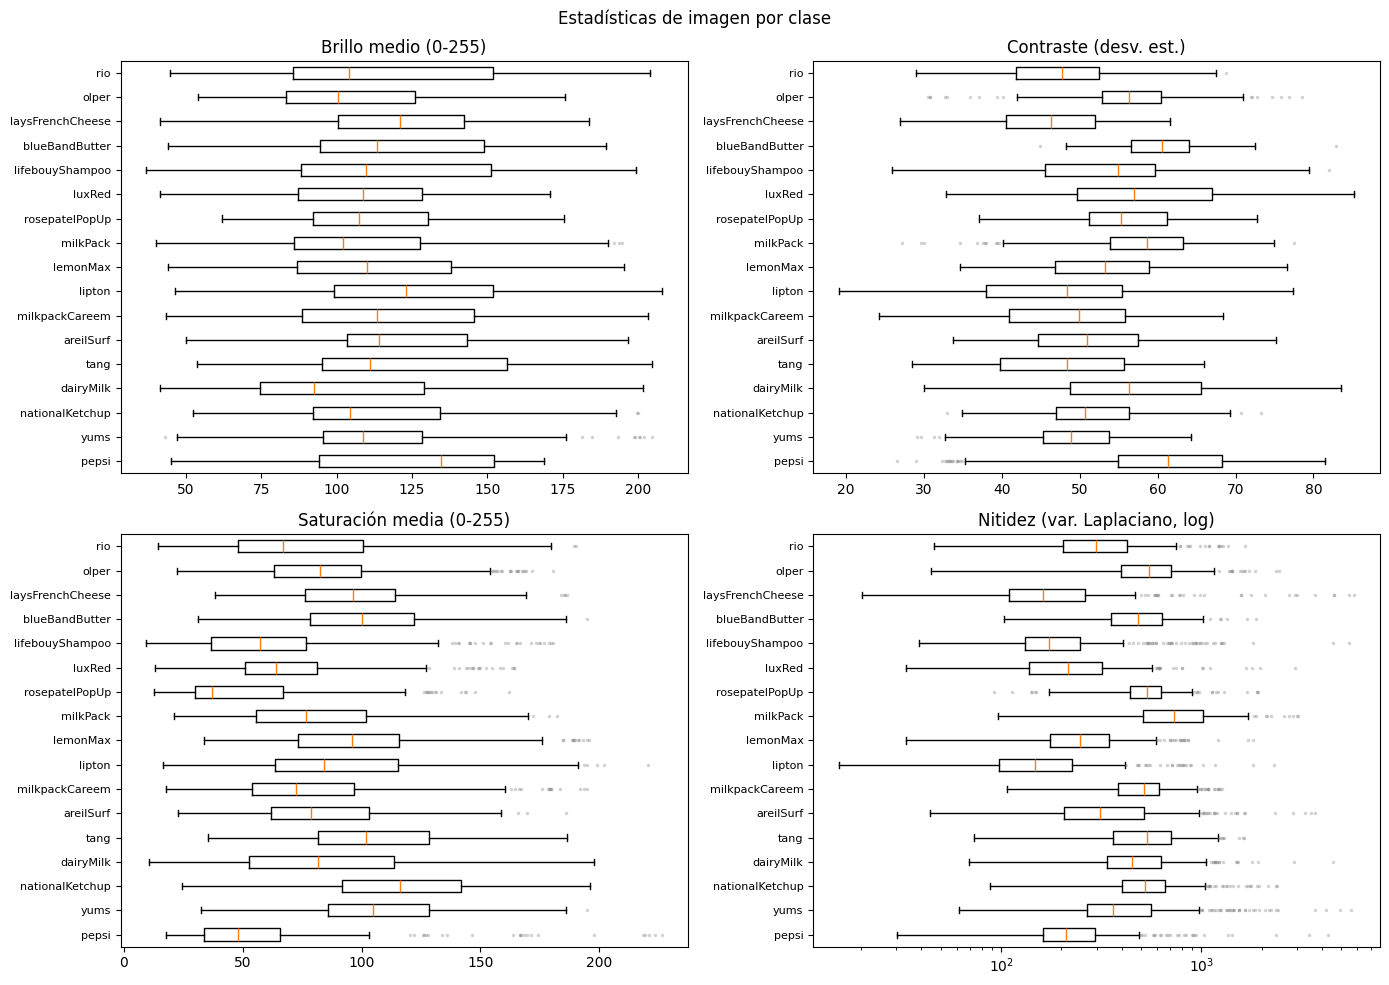

,brillo_medio,contraste_std,saturacion_media,nitidez_lapvar
pepsi,0,16,23,25
yums,10,4,1,37
nationalKetchup,2,3,0,24
dairyMilk,0,0,0,17
tang,0,0,0,8
areilSurf,0,0,3,23
milkpackCareem,0,0,14,17
lipton,0,0,5,25
lemonMax,0,0,12,20
milkPack,3,12,3,10


In [1]:
from google.colab import drive
drive.mount("/content/drive")
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/tesis_retail")
manifest = pd.read_csv(PROJECT_DIR / "manifest" / "manifest_v0.csv")

metricas = [("brillo_medio", "Brillo medio (0-255)"), ("contraste_std", "Contraste (desv. est.)"),
            ("saturacion_media", "Saturación media (0-255)"), ("nitidez_lapvar", "Nitidez (var. Laplaciano, log)")]
orden = sorted(manifest["clase"].dropna().unique())
atipicos = dict(marker="o", markersize=2.5, alpha=0.35, markeredgewidth=0, markerfacecolor="gray")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (col, titulo) in zip(axes.ravel(), metricas):
    datos = [manifest.loc[manifest["clase"] == c, col].dropna() for c in orden]
    ax.boxplot(datos, vert=False, showfliers=True, flierprops=atipicos)
    ax.set_yticks(range(1, len(orden) + 1))
    ax.set_yticklabels([c.split("-")[1] if c.count("-") >= 2 else c for c in orden], fontsize=8)
    if col == "nitidez_lapvar":
        ax.set_xscale("log")
    ax.set_title(titulo)
fig.suptitle("Estadísticas de imagen por clase")
fig.tight_layout()
fig.savefig(PROJECT_DIR / "eda" / "01_estadisticas_por_clase_con_atipicos.png", dpi=200, bbox_inches="tight")
plt.show()

# Cantidad de atípicos por clase y estadística (regla de 1.5 × rango intercuartílico)
def n_atipicos(s):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return int(((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).sum())
resumen_atip = manifest.groupby("clase")[[m for m, _ in metricas]].agg(n_atipicos)
resumen_atip.index = [c.split("-")[1] for c in resumen_atip.index]
resumen_atip.loc["TOTAL"] = resumen_atip.sum()
resumen_atip

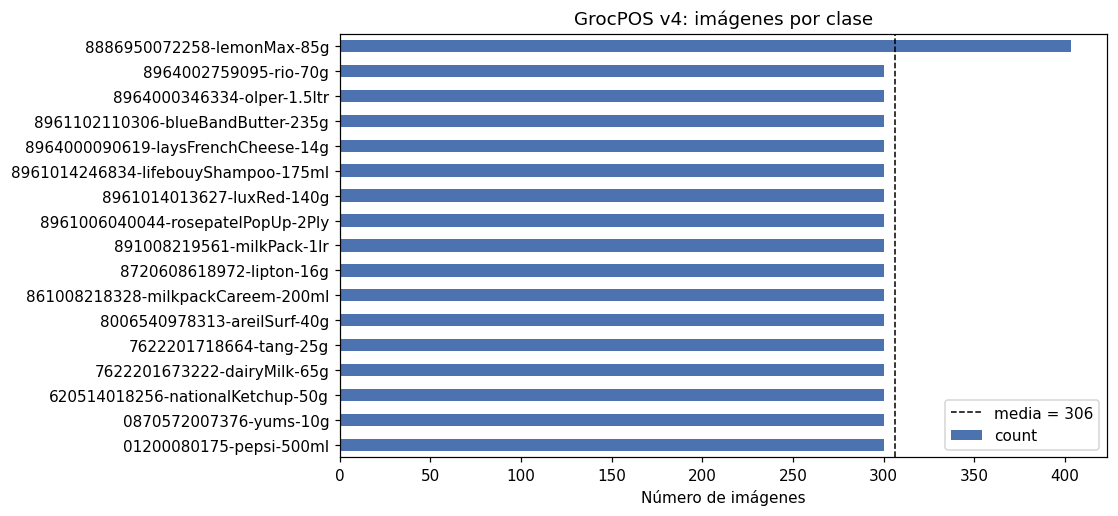

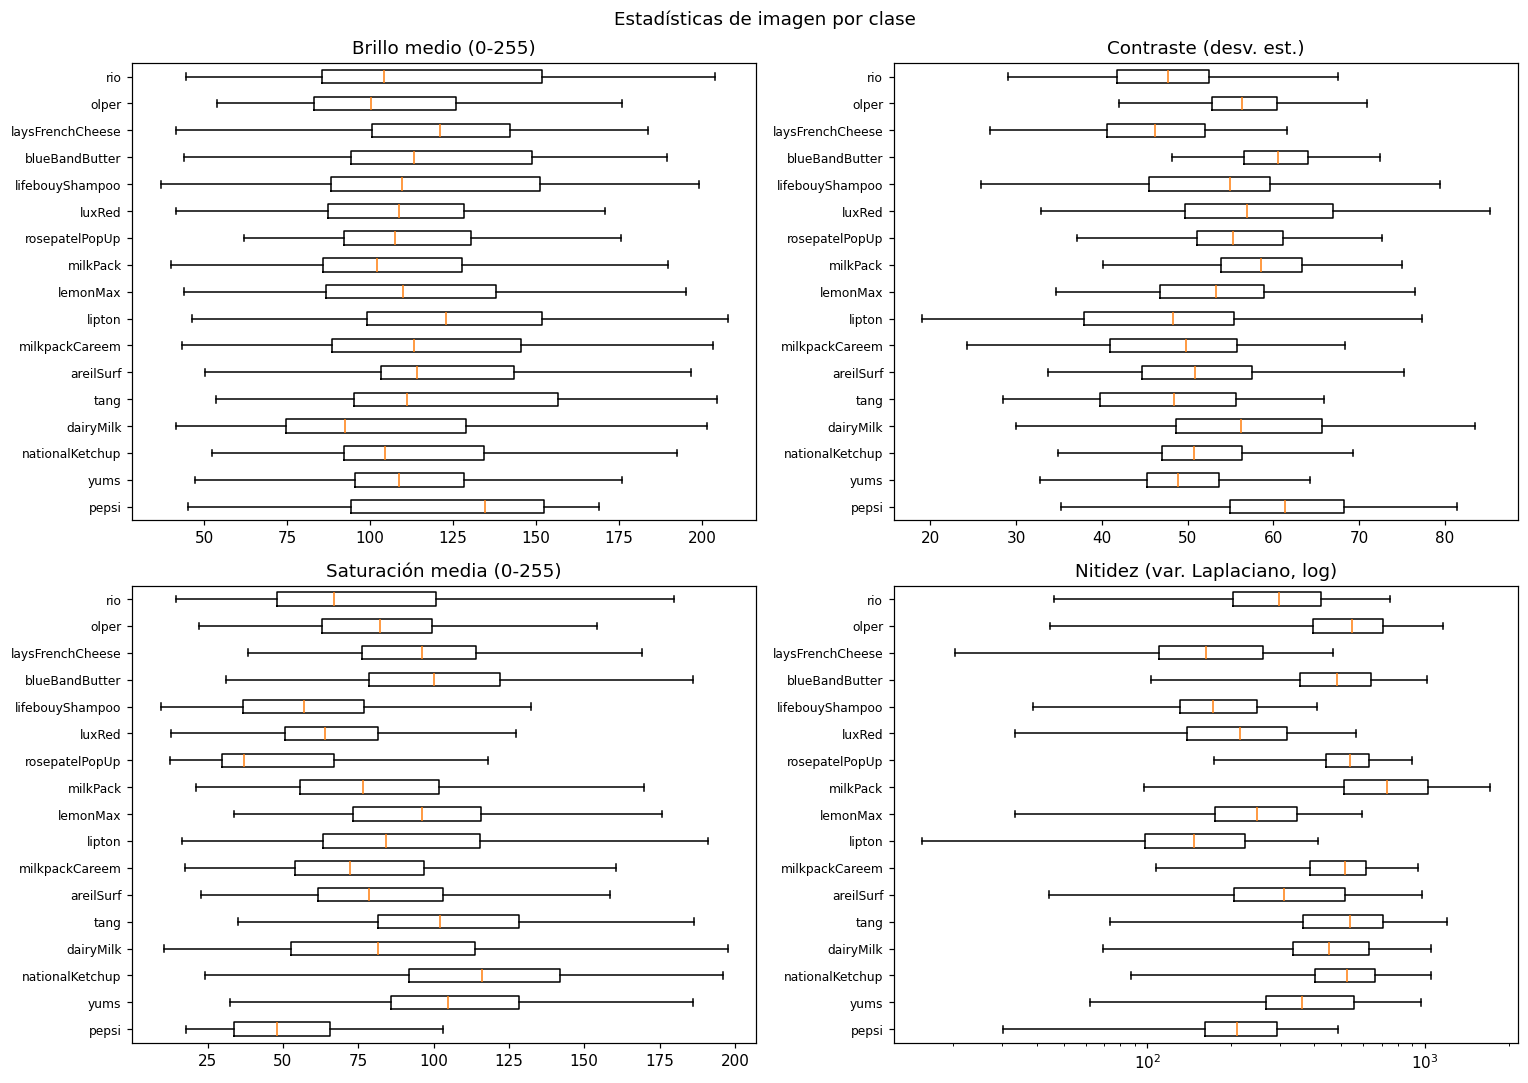

,n,brillo_medio,contraste_std,saturacion_media,nitidez_lapvar
clase,,,,,
01200080175-pepsi-500ml,300,134.5,61.3,48.1,211.2
0870572007376-yums-10g,300,108.6,48.8,104.9,361.1
620514018256-nationalKetchup-50g,300,104.5,50.7,116.2,521.8
7622201673222-dairyMilk-65g,300,92.6,56.3,81.6,452.8
7622201718664-tang-25g,300,111.1,48.4,102.1,536.2
8006540978313-areilSurf-40g,300,114.1,50.9,78.7,310.6
861008218328-milkpackCareem-200ml,300,113.3,49.9,72.3,515.8
8720608618972-lipton-16g,300,122.9,48.3,84.3,147.3
8886950072258-lemonMax-85g,403,110.0,53.3,96.1,247.9


In [ ]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

# 14.1 Imágenes por clase
fig, ax = plt.subplots(figsize=(9, 5))
conteo.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.axvline(conteo.mean(), ls="--", c="k", lw=1, label=f"media = {conteo.mean():.0f}")
ax.set_xlabel("Número de imágenes"); ax.set_ylabel(""); ax.legend()
ax.set_title("GrocPOS v4: imágenes por clase")
fig.savefig(DIRS["eda"] / "01_imagenes_por_clase.png"); plt.show()

# 14.2 Distribuciones por clase
metricas = [("brillo_medio", "Brillo medio (0-255)"), ("contraste_std", "Contraste (desv. est.)"),
            ("saturacion_media", "Saturación media (0-255)"), ("nitidez_lapvar", "Nitidez (var. Laplaciano, log)")]
orden = conteo.index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (col, titulo) in zip(axes.ravel(), metricas):
    datos = [manifest.loc[manifest["clase"] == c, col].dropna() for c in orden]
    ax.boxplot(datos, vert=False, showfliers=False)
    ax.set_yticks(range(1, len(orden) + 1))
    ax.set_yticklabels([c.split("-")[1] if c.count("-") >= 2 else c for c in orden], fontsize=8)
    if col == "nitidez_lapvar":
        ax.set_xscale("log")
    ax.set_title(titulo)
fig.suptitle("Estadísticas de imagen por clase")
fig.tight_layout(); fig.savefig(DIRS["eda"] / "01_estadisticas_por_clase.png"); plt.show()

# Tabla resumen para la tesis
tabla = manifest.groupby("clase")[[m for m, _ in metricas]].median().round(1)
tabla.insert(0, "n", conteo)
tabla.to_csv(DIRS["eda"] / "01_tabla_estadisticas_por_clase.csv")
tabla

## Paso 15 · Mallas de inspección visual por clase
Se guarda una malla de 5×5 imágenes aleatorias por clase en `eda/grids/`. Revísalas y anota observaciones en la tabla del Paso 16.

Mallas:   0%|          | 0/17 [00:00<?, ?it/s]

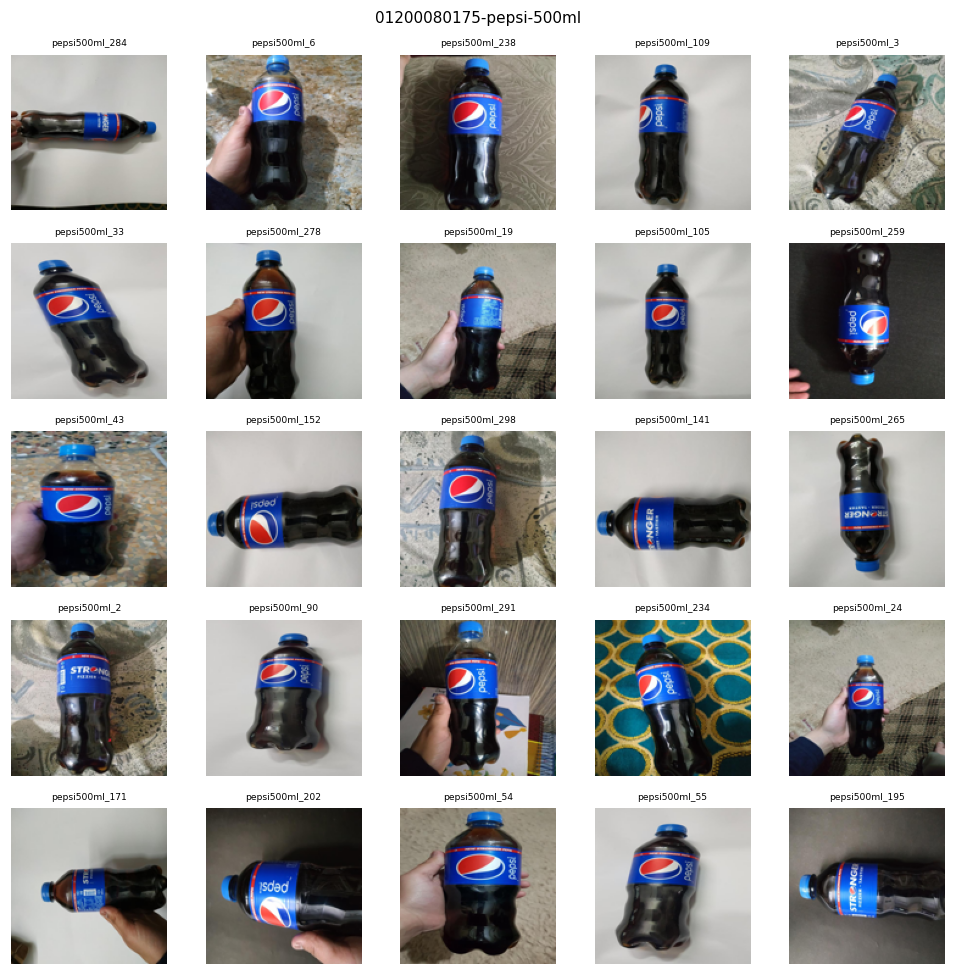

Mallas guardadas en: /content/drive/MyDrive/tesis_retail/eda/grids


In [ ]:
N_MALLA = 25
def malla_clase(clase, n=N_MALLA, lado=128):
    sub = manifest[(manifest["clase"] == clase) & manifest["abre_ok"]]
    muestra = sub.sample(min(n, len(sub)), random_state=SEED)
    filas = int(np.ceil(np.sqrt(len(muestra))))
    fig, axes = plt.subplots(filas, filas, figsize=(filas * 1.8, filas * 1.8))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), muestra.iterrows()):
        with Image.open(EXTRACT_DIR / r["ruta_rel"]) as im:
            ax.imshow(im.convert("RGB").resize((lado, lado)))
        ax.set_title(r["nombre_original"][:16], fontsize=6)
    fig.suptitle(clase, fontsize=10)
    fig.tight_layout()
    fig.savefig(DIRS["eda/grids"] / f"grid_{clase}.png")
    return fig

for c in tqdm(clases, desc="Mallas"):
    f = malla_clase(c)
    plt.close(f)

# Muestra en pantalla una de ejemplo
malla_clase(clases[0]); plt.show()
print("Mallas guardadas en:", DIRS["eda/grids"])

## Paso 16 · Registro de inspección visual (plantilla)

Se crea un CSV con una fila por clase para que lo completes al revisar las mallas. Estas observaciones justifican las decisiones de recorte, resolución y filtrado.

In [ ]:
PLANTILLA = DIRS["eda"] / "01_inspeccion_visual.csv"
if not PLANTILLA.exists():
    pd.DataFrame({
        "clase": clases,
        "fondo": "", "angulos_variados": "", "iluminacion": "", "manos_u_oclusion": "",
        "varios_productos": "", "fraccion_ocupada_producto": "", "deformacion_por_stretch": "",
        "texto_logo_legible": "", "parecido_con_otra_clase": "", "notas": "",
    }).to_csv(PLANTILLA, index=False)
    print("Plantilla creada:", PLANTILLA)
else:
    print("La plantilla ya existe (no se sobrescribe):", PLANTILLA)

Plantilla creada: /content/drive/MyDrive/tesis_retail/eda/01_inspeccion_visual.csv


## Paso 17 · Cierre y checklist

Antes de pasar al notebook 02 verifica:

- [ ] Hay 5203 imágenes, 17 clases, todas 640×640, ninguna corrupta.
- [ ] Revisaste los grupos de `phash` idéntico y, sobre todo, los que mezclan clases.
- [ ] Revisaste las imágenes con prefijo no dominante (posibles errores de etiqueta).
- [ ] Completaste `01_inspeccion_visual.csv` mirando las 17 mallas.
- [ ] Anotaste en tu bitácora de tesis el SHA-256 del zip y las versiones de librerías (están en `logs/01_inventario.json`).

**Siguiente notebook (02):** embeddings (GPU), agrupación de casi duplicados (`group_id`) y distancia real-real al vecino más cercano.

In [ ]:
print(json.dumps({"imagenes": qc["n_imagenes"], "clases": qc["n_clases"], "corruptas": qc["corruptas"],
                  "tamanos": str(qc["tamanos"]), "dup_md5_grupos": len(r_md5), "dup_phash_grupos": len(r_ph),
                  "phash_conflicto_clase": len(conflicto), "prefijo_no_dominante": len(sospechosas)},
                 indent=2, ensure_ascii=False))

{
  "imagenes": 5203,
  "clases": 17,
  "corruptas": 0,
  "tamanos": "{(640, 640): 5203}",
  "dup_md5_grupos": 103,
  "dup_phash_grupos": 110,
  "phash_conflicto_clase": 0,
  "prefijo_no_dominante": 7
}


In [ ]:
dup = manifest[manifest["dup_md5"]]
print(dup.groupby("md5").size().value_counts())          # ¿todos los grupos son de 2 copias?
print(dup["clase"].value_counts())                       # ¿todos en lemonMax?
solo_phash = manifest[manifest["dup_phash_exacto"] & ~manifest["dup_md5"]]
print(solo_phash["clase"].value_counts())                # los 7 grupos extra de phash

2    103
Name: count, dtype: int64
clase
8886950072258-lemonMax-85g    206
Name: count, dtype: int64
clase
8961006040044-rosepatelPopUp-2Ply      4
8961014246834-lifebouyShampoo-175ml    4
0870572007376-yums-10g                 2
8964000090619-laysFrenchCheese-14g     2
8964000346334-olper-1.5ltr             2
Name: count, dtype: int64


In [ ]:
log = json.loads(LOG_PATH.read_text())
print("SHA-256 del zip:", log["zip"]["sha256"])
print(json.dumps(log["entorno"], indent=2))

SHA-256 del zip: 44761579452d3ae9a84b9fa511a38b9c60bc98d83b762fe44fac3d97395fc105
{
  "python": "3.13.16",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "opencv": "5.0.0",
  "imagehash": "4.3.2",
  "matplotlib": "3.10.0",
  "fecha_ejecucion_utc": "2026-10-08T03:26:06+00:00",
  "seed": 42
}


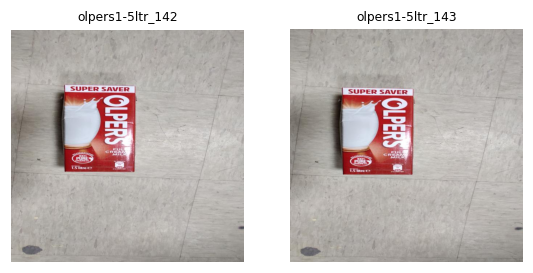

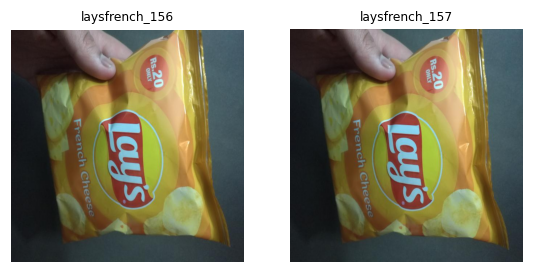

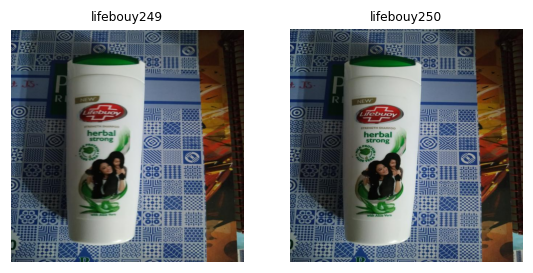

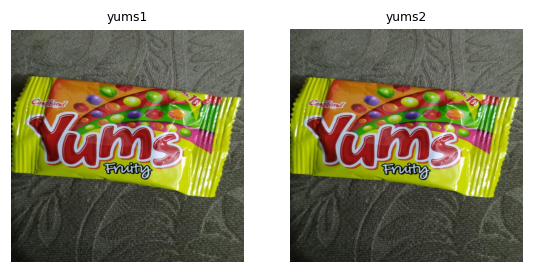

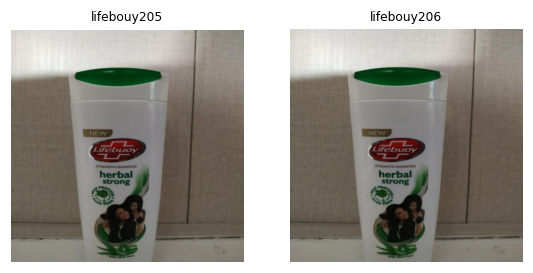

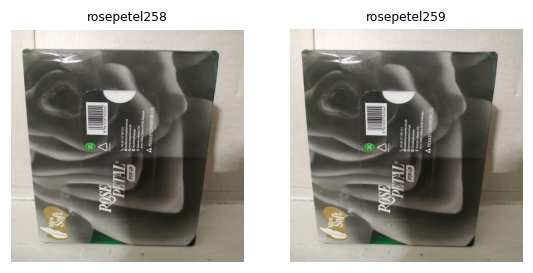

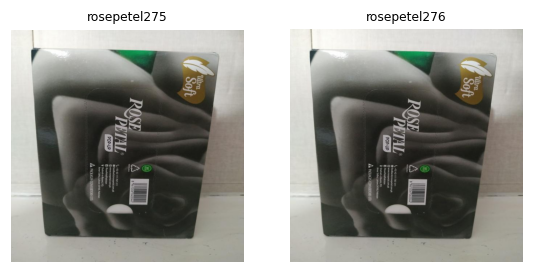

In [ ]:
for ph, g in solo_phash.groupby("phash"):
    fig, axes = plt.subplots(1, len(g), figsize=(3 * len(g), 3))
    for ax, (_, r) in zip(np.ravel(axes), g.iterrows()):
        ax.imshow(Image.open(EXTRACT_DIR / r["ruta_rel"])); ax.axis("off")
        ax.set_title(r["nombre_original"][:20], fontsize=8)
    plt.show()

In [ ]:
a=2;b=3;print(a+b)

5
